In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Generate sample data

Sample size: 200
Sample mean: 48.206
Sample std:  45.582


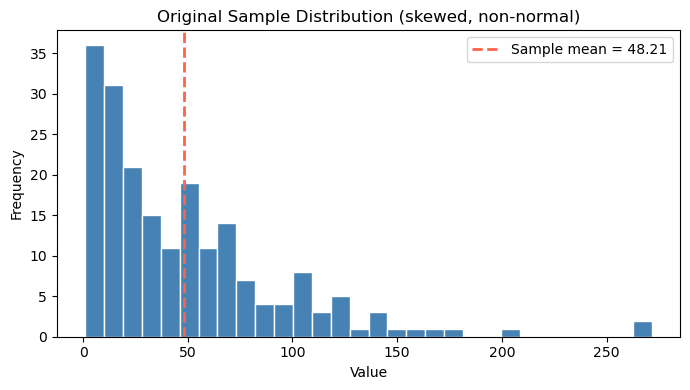

In [5]:
rng = np.random.default_rng(42)

# Simulate a skewed dataset (e.g. income-like data)
data = rng.exponential(scale=50, size=200)

print(f'Sample size: {len(data)}')
print(f'Sample mean: {data.mean():.3f}')
print(f'Sample std:  {data.std():.3f}')

plt.figure(figsize=(7, 4))
plt.hist(data, bins=30, color='steelblue', edgecolor='white')
plt.axvline(data.mean(), color='tomato', lw=2, ls='--', label=f'Sample mean = {data.mean():.2f}')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Original Sample Distribution (skewed, non-normal)')
plt.legend()
plt.tight_layout()
plt.savefig('original_sample.png', dpi=150)
plt.show()

### Original Sample Distribution

The histogram shows 200 data points drawn from an exponential distribution with a sample mean of 48.21 and standard deviation of 45.58. The distribution is strongly right-skewed — the majority of values cluster near zero with a long tail extending beyond 200. This deliberate choice of a non-normal distribution motivates the use of Bootstrap: traditional confidence interval formulas assume normality, which would be a poor assumption here.

直方图展示了200个来自指数分布的数据点，样本均值为48.21，标准差为45.58。分布明显右偏——大多数值集中在零附近，右侧有长尾延伸至200以上。故意选择非正态分布是为了体现Bootstrap的价值：传统置信区间公式假设数据正态分布，而这里显然不满足该假设。

# Core Bootstrap function

In [8]:
def bootstrap_statistic(data: np.ndarray, statistic_func, n_iterations: int = 10_000, seed: int = 42):
    """
    Estimate the sampling distribution of a statistic using Bootstrap resampling.

    Args:
        data: 1D array of observed sample data
        statistic_func: function that takes an array and returns a single number
                         (e.g. np.mean, np.median)
        n_iterations: number of bootstrap resamples to draw
        seed: random seed for reproducibility

    Returns:
        bootstrap_estimates: array of the statistic computed on each resample
    """
    rng = np.random.default_rng(seed)
    n = len(data)
    bootstrap_estimates = np.empty(n_iterations)

    for i in range(n_iterations):
        # Resample with replacement, same size as original data
        resample = rng.choice(data, size=n, replace=True)
        bootstrap_estimates[i] = statistic_func(resample)

    return bootstrap_estimates

# Run Bootstrap on the sample mean

In [11]:
boot_means = bootstrap_statistic(data, np.mean, n_iterations=10_000)

# 95% confidence interval via percentile method
ci_lower, ci_upper = np.percentile(boot_means, [2.5, 97.5])

print(f'Original sample mean:     {data.mean():.3f}')
print(f'Bootstrap mean of means:  {boot_means.mean():.3f}')
print(f'Bootstrap std error:      {boot_means.std():.3f}')
print(f'95% Confidence Interval:  ({ci_lower:.3f}, {ci_upper:.3f})')

Original sample mean:     48.206
Bootstrap mean of means:  48.143
Bootstrap std error:      3.189
95% Confidence Interval:  (42.094, 54.550)


# Visualization 1: Bootstrap sampling distribution

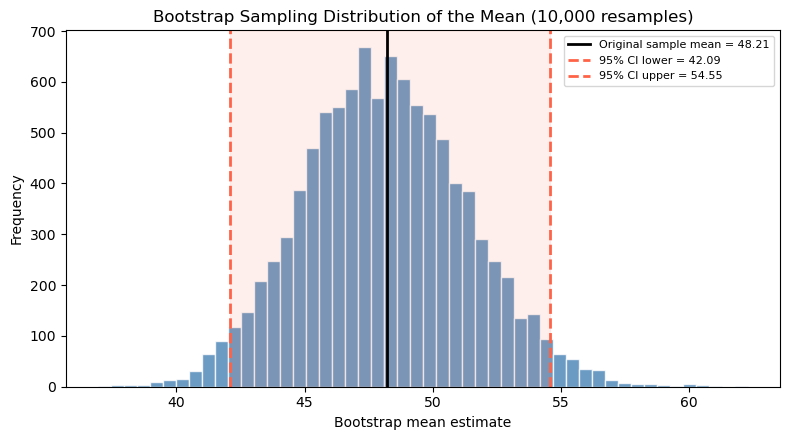

In [14]:
plt.figure(figsize=(8, 4.5))
plt.hist(boot_means, bins=50, color='steelblue', edgecolor='white', alpha=0.8)

plt.axvline(data.mean(), color='black', lw=2, label=f'Original sample mean = {data.mean():.2f}')
plt.axvline(ci_lower, color='tomato', lw=2, ls='--', label=f'95% CI lower = {ci_lower:.2f}')
plt.axvline(ci_upper, color='tomato', lw=2, ls='--', label=f'95% CI upper = {ci_upper:.2f}')

plt.axvspan(ci_lower, ci_upper, color='tomato', alpha=0.1)

plt.xlabel('Bootstrap mean estimate')
plt.ylabel('Frequency')
plt.title('Bootstrap Sampling Distribution of the Mean (10,000 resamples)')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('bootstrap_distribution.png', dpi=150)
plt.show()

### Bootstrap Sampling Distribution of the Mean

Despite the original data being heavily skewed, the Bootstrap sampling distribution of the mean is approximately bell-shaped — a direct demonstration of the Central Limit Theorem in action. Across 10,000 resamples, the mean estimates concentrate around 48.21, with a 95% confidence interval of (42.09, 54.55). The shaded region captures the central 95% of all Bootstrap estimates, providing an empirically derived interval without any distributional assumption.

尽管原始数据严重右偏，Bootstrap均值的抽样分布却近似呈钟形——这正是中心极限定理的直观体现。在10000次重抽样中，均值估计集中在48.21附近，95%置信区间为（42.09，54.55）。阴影区域覆盖了所有Bootstrap估计值的中间95%，在不做任何分布假设的前提下，纯经验地给出了置信区间。

# Visualization 2: CI stability vs. number of resamples

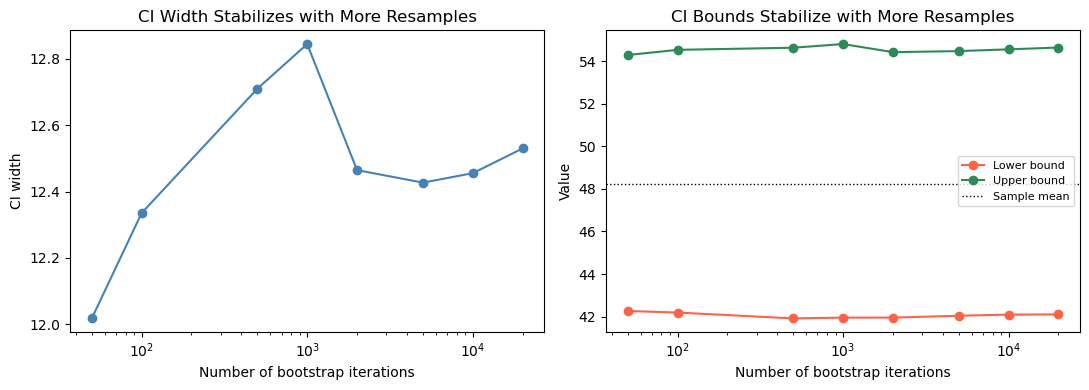

In [17]:
iteration_counts = [50, 100, 500, 1_000, 2_000, 5_000, 10_000, 20_000]
ci_widths = []
ci_lowers = []
ci_uppers = []

for n_iter in iteration_counts:
    boot = bootstrap_statistic(data, np.mean, n_iterations=n_iter, seed=42)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    ci_lowers.append(lo)
    ci_uppers.append(hi)
    ci_widths.append(hi - lo)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.semilogx(iteration_counts, ci_widths, marker='o', color='steelblue')
ax1.set_xlabel('Number of bootstrap iterations')
ax1.set_ylabel('CI width')
ax1.set_title('CI Width Stabilizes with More Resamples')

ax2.semilogx(iteration_counts, ci_lowers, marker='o', color='tomato', label='Lower bound')
ax2.semilogx(iteration_counts, ci_uppers, marker='o', color='seagreen', label='Upper bound')
ax2.axhline(data.mean(), color='black', lw=1, ls=':', label='Sample mean')
ax2.set_xlabel('Number of bootstrap iterations')
ax2.set_ylabel('Value')
ax2.set_title('CI Bounds Stabilize with More Resamples')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig('bootstrap_stability.png', dpi=150)
plt.show()

### CI Stability

Both plots show that the confidence interval stabilizes rapidly. The CI width fluctuates between iterations 50–1,000 but settles around 12.4–12.5 from 2,000 iterations onward. Similarly, the lower and upper bounds converge to approximately 42.1 and 54.5 respectively, with minimal variation beyond 1,000 iterations. This confirms that 10,000 resamples is more than sufficient for a stable estimate — in practice, even 2,000–5,000 iterations would give reliable results for this dataset.

两张图都显示置信区间迅速趋于稳定。区间宽度在50-1000次迭代之间有所波动，但从2000次起稳定在约12.4-12.5。同样，上下界分别收敛到约54.5和42.1，1000次以上变化极小。这说明10000次重抽样对于稳定估计来说绰绰有余——实际上对这个数据集而言，2000-5000次迭代就已经能给出可靠结果。

# Compare Bootstrap to traditional (normal-theory) CI

In [20]:
n = len(data)
se_traditional = data.std(ddof=1) / np.sqrt(n)
ci_traditional = (data.mean() - 1.96 * se_traditional, data.mean() + 1.96 * se_traditional)

print('Comparison of 95% Confidence Intervals')
print('-' * 45)
print(f'Bootstrap method:    ({ci_lower:.3f}, {ci_upper:.3f})')
print(f'Traditional method:  ({ci_traditional[0]:.3f}, {ci_traditional[1]:.3f})')

Comparison of 95% Confidence Intervals
---------------------------------------------
Bootstrap method:    (42.094, 54.550)
Traditional method:  (41.873, 54.539)


# Bonus: Bootstrap on the median (no closed-form formula exists)

Original sample median:   34.245
95% CI for median:        (26.477, 45.754)


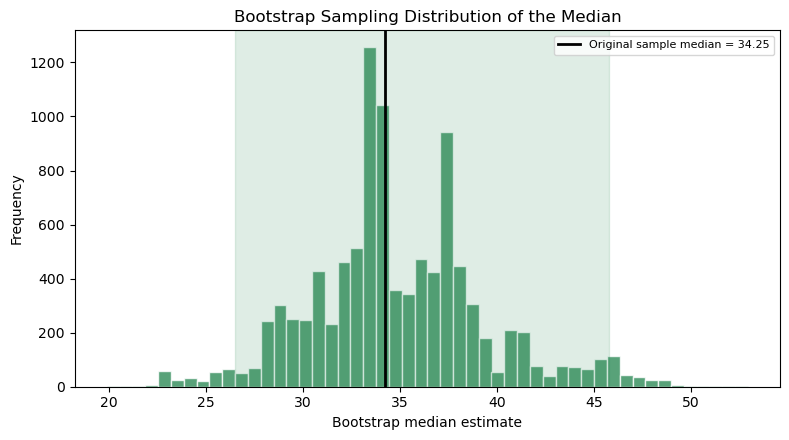

In [23]:
boot_medians = bootstrap_statistic(data, np.median, n_iterations=10_000)
median_ci_lower, median_ci_upper = np.percentile(boot_medians, [2.5, 97.5])

print(f'Original sample median:   {np.median(data):.3f}')
print(f'95% CI for median:        ({median_ci_lower:.3f}, {median_ci_upper:.3f})')

plt.figure(figsize=(8, 4.5))
plt.hist(boot_medians, bins=50, color='seagreen', edgecolor='white', alpha=0.8)
plt.axvline(np.median(data), color='black', lw=2, label=f'Original sample median = {np.median(data):.2f}')
plt.axvspan(median_ci_lower, median_ci_upper, color='seagreen', alpha=0.15)
plt.xlabel('Bootstrap median estimate')
plt.ylabel('Frequency')
plt.title('Bootstrap Sampling Distribution of the Median')
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig('bootstrap_median.png', dpi=150)
plt.show()

### Bootstrap Sampling Distribution of the Median

The Bootstrap distribution of the median is notably more irregular than that of the mean — it shows a jagged, multi-peaked shape rather than a smooth bell curve. This is because the median is a discrete function of the data: small changes in the resample can cause the median to “jump” between values. The 95% confidence interval (26.48, 45.75) is substantially wider than the mean’s CI, reflecting the higher variability of the median as an estimator. Crucially, this result required no special formula — Bootstrap handled the median exactly the same way as the mean.

中位数的Bootstrap分布明显比均值的分布更不规则——呈现出锯齿状的多峰形态，而非平滑的钟形曲线。这是因为中位数是数据的离散函数：重抽样的微小变化就可能导致中位数在不同值之间”跳跃”。95%置信区间为（26.48，45.75），明显比均值的置信区间更宽，反映了中位数作为估计量的更高变异性。关键在于：这个结果不需要任何特殊公式——Bootstrap对中位数和均值采用了完全相同的处理流程。

# Bootstrap Confidence Intervals — Project Summary

This project implements the Bootstrap resampling method to estimate the sampling distribution and confidence interval of a statistic (mean and median), without relying on any distributional assumptions about the underlying data.

The sample data was simulated from an exponential distribution — deliberately chosen to be skewed and non-normal — to highlight Bootstrap's key advantage over traditional parametric methods. The core algorithm draws 10,000 resamples with replacement from the original sample, computes the target statistic on each resample, and uses the resulting distribution of statistics to construct a 95% confidence interval via the percentile method (the 2.5th and 97.5th percentiles).

The project includes several layers of analysis:

1. A visualization of the Bootstrap sampling distribution, illustrating the uncertainty around the mean estimate;
2. A stability analysis, showing how the confidence interval converges and stabilizes as the number of resamples increases from 50 to 20,000 — providing empirical guidance on how many iterations are actually needed in practice;
3. A comparison with the traditional normal-theory method, contrasting the Bootstrap result against the standard formula (mean ± 1.96 × standard error) based on a normality assumption;
4. A Bootstrap application to the median, demonstrating the method's true value — statistics like the median have no simple closed-form formula for their standard error, yet Bootstrap handles them with the exact same procedure, free from the assumptions that limit traditional approaches.

Overall, the project moves from method fundamentals to empirical validation of stability and consistency with traditional theory, and finally to a case where Bootstrap succeeds where classical methods fall short — demonstrating both the core logic and practical value of nonparametric statistical inference.

# Bootstrap 置信区间 — 项目总结

样本数据来自指数分布——故意选择偏态、非正态的分布——以突出 Bootstrap 相对于传统参数方法的核心优势。算法从原始样本中进行10000次有放回重抽样，对每次重抽样计算目标统计量，并通过百分位法（第2.5与第97.5百分位数）构造95%置信区间。

本项目包含以下几个层次的分析：

1.Bootstrap 抽样分布可视化，展示均值估计的不确定性范围，并直观呈现中心极限定理的效果；

2.稳定性分析，展示置信区间随重抽样次数从50增加到20000时逐渐收敛稳定的过程，为实际操作中的迭代次数选择提供经验依据；

3.与传统正态理论方法的对比，将 Bootstrap 结果与基于正态分布假设的标准公式（均值 ± 1.96 × 标准误）进行对照；

4.对中位数的 Bootstrap 应用，展示该方法的真正价值所在——中位数等统计量没有简单的标准误解析公式，而 Bootstrap 用完全相同的流程处理，不受传统方法假设的限制。

整体而言，本项目从方法基础出发，依次验证了稳定性、与传统理论的一致性，以及在传统方法失效场景下的适用性——展示了非参数统计推断的核心逻辑与实践价值。